In [48]:
import pandas as pd

In [49]:
df = pd.read_csv("../Data/raw/lfsa_ergaed__custom_23902772_linear_2_0.csv")# первая таблица 

'''Comprobamos ### H1. Educación y empleo en Europa
**Hipótesis:** Las personas con un nivel educativo más alto presentan una mayor tasa de empleo. 
La magnitud de esta relación varía entre los países europeos.'''

In [50]:
df.head()

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,unit,Unit of measure,sex,Sex,age,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2015,NaN,49.1,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2016,NaN,49.9,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2017,NaN,49.9,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2018,NaN,50.6,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2019,NaN,50.5,NaN,NaN,NaN,NaN,NaN


In [51]:
df["TIME_PERIOD"].unique() #gthbjl 2015 - 2025

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025])

H1: образование и занятость в европейских странах
H2–H3: различия в занятости по миграционному статусу и образованию.
H4: когнитивные навыки и доходы в Испании — отдельный анализ OECD PIAAC.

In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7218 entries, 0 to 7217
Data columns (total 23 columns):
 #   Column                                                           Non-Null Count  Dtype  
---  ------                                                           --------------  -----  
 0   STRUCTURE                                                        7218 non-null   str    
 1   STRUCTURE_ID                                                     7218 non-null   str    
 2   STRUCTURE_NAME                                                   7218 non-null   str    
 3   freq                                                             7218 non-null   str    
 4   Time frequency                                                   7218 non-null   str    
 5   unit                                                             7218 non-null   str    
 6   Unit of measure                                                  7218 non-null   str    
 7   sex                                                  

In [53]:
df.shape

(7218, 23)

In [54]:
df["TIME_PERIOD"].min(), df["TIME_PERIOD"].max() # период

(np.int64(2015), np.int64(2025))

In [55]:
df["geo"].nunique() # кол-во стран

38

In [56]:
df["isced11"].unique() # категории образования: 
# ED0-2: Начальное и основное образование или ниже.
# ED3_4:Среднее образование и послесреднее, не являющееся высшим. 
# ED5-8: Короткий цикл высшего образования, бакалавриат, магистратура, докторантура..

<StringArray>
['ED0-2', 'ED3_4', 'ED5-8']
Length: 3, dtype: str

In [57]:
# Удаляем столбцы, которые полностью пустые
df = df.dropna(axis=1, how="all")

In [58]:

df.shape
# Проверяем обновлённую структуру

(7218, 19)

In [59]:
df[["sex", "age", "isced11", "OBS_VALUE"]].head() 

,sex,age,isced11,OBS_VALUE
0,F,Y25-64,ED0-2,49.1
1,F,Y25-64,ED0-2,49.9
2,F,Y25-64,ED0-2,49.9
3,F,Y25-64,ED0-2,50.6
4,F,Y25-64,ED0-2,50.5


## H1. Educación y empleo en Europa

### Fuente de datos
- Organismo: Eurostat
- Dataset: lfsa_ergaed
- Archivo: lfsa_ergaed__custom_23902772_linear_2_0.csv
- Periodo analizado: 2015–2025
- Cobertura geográfica: 38 países/territorios
- Número de registros iniciales: 7.218
- Número de columnas iniciales: 23

### Hipótesis
Las personas con un nivel educativo más alto presentan una mayor tasa de empleo. La magnitud de esta relación varía entre los países europeos.

### Variables principales
| Variable | Descripción |
|---|---|
| geo | País o territorio |
| TIME_PERIOD | Año de observación |
| isced11 | Nivel educativo (clasificación ISCED 2011) |
| sex | Sexo |
| age | Grupo de edad |
| OBS_VALUE | Tasa de empleo (%) |

### Categorías educativas
- ED0-2: Educación baja (ISCED 0–2)
- ED3_4: Educación media (ISCED 3–4)
- ED5-8: Educación alta (ISCED 5–8)

### Análisis previsto
Comparar las tasas de empleo por nivel educativo, país y año.

In [60]:
df["sex"].unique(), df["age"].unique()

(<StringArray>
 ['F', 'M', 'T']
 Length: 3, dtype: str,
 <StringArray>
 ['Y25-64', 'Y25-74']
 Length: 2, dtype: str)

In [61]:
df["geo"].unique()

<StringArray>
[       'AT',        'BA',        'BE',        'BG',        'CH',        'CY',
        'CZ',        'DE',        'DK',      'EA21',        'EE',        'EL',
        'ES', 'EU27_2020',        'FI',        'FR',        'HR',        'HU',
        'IE',        'IS',        'IT',        'LT',        'LU',        'LV',
        'ME',        'MK',        'MT',        'NL',        'NO',        'PL',
        'PT',        'RO',        'RS',        'SE',        'SI',        'SK',
        'TR',        'UK']
Length: 38, dtype: str

In [62]:
df["age"].unique()

<StringArray>
['Y25-64', 'Y25-74']
Length: 2, dtype: str

In [63]:
df = df[df["age"] == "Y25-64"]# оставляем только возрастную группу 25-64

In [64]:
df["sex"].unique()

<StringArray>
['F', 'M', 'T']
Length: 3, dtype: str

In [65]:
df = df[df["sex"] == "T"] # оставляем только общий показатель по полу

In [66]:
df.shape

(1203, 19)

In [67]:
df["isced11"].unique()

<StringArray>
['ED0-2', 'ED3_4', 'ED5-8']
Length: 3, dtype: str

In [68]:
df["geo"].unique()

<StringArray>
[       'AT',        'BA',        'BE',        'BG',        'CH',        'CY',
        'CZ',        'DE',        'DK',      'EA21',        'EE',        'EL',
        'ES', 'EU27_2020',        'FI',        'FR',        'HR',        'HU',
        'IE',        'IS',        'IT',        'LT',        'LU',        'LV',
        'ME',        'MK',        'MT',        'NL',        'NO',        'PL',
        'PT',        'RO',        'RS',        'SE',        'SI',        'SK',
        'TR',        'UK']
Length: 38, dtype: str

In [69]:
df = df[~df["geo"].isin(["EU27_2020", "EA21"])]

In [70]:
df.shape

(1137, 19)

In [71]:
df["TIME_PERIOD"].unique()

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025])

In [72]:
df.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Time frequency',
       'unit', 'Unit of measure', 'sex', 'Sex', 'age', 'Age class', 'isced11',
       'International Standard Classification of Education (ISCED 2011)',
       'geo', 'Geopolitical entity (reporting)', 'TIME_PERIOD', 'OBS_VALUE',
       'OBS_FLAG', 'Observation status (Flag) V2 structure'],
      dtype='str')

H1 ключевые столбцы:
- geo — страна
- TIME_PERIOD — год
- isced11 — уровень образования
- OBS_VALUE — показатель занятости
- sex — пол
- age — возрастная группа

In [73]:
df["unit"].unique()

<StringArray>
['PC']
Length: 1, dtype: str

In [74]:
df["OBS_VALUE"].describe()

count    1137.000000
mean       72.200352
std        15.066978
min        24.200000
25%        61.100000
50%        75.300000
75%        85.100000
max        93.600000
Name: OBS_VALUE, dtype: float64

In [75]:
df.isnull().sum()

STRUCTURE                                                            0
STRUCTURE_ID                                                         0
STRUCTURE_NAME                                                       0
freq                                                                 0
Time frequency                                                       0
unit                                                                 0
Unit of measure                                                      0
sex                                                                  0
Sex                                                                  0
age                                                                  0
Age class                                                            0
isced11                                                              0
International Standard Classification of Education (ISCED 2011)      0
geo                                                                  0
Geopol

In [76]:
df["OBS_FLAG"].value_counts(dropna=False)

OBS_FLAG
NaN    963
b      144
d       21
bd       9
Name: count, dtype: int64

In [77]:
df.duplicated(subset=["geo", "TIME_PERIOD", "isced11"]).sum() # функция для проверки дубликатов по столбцам geo, TIME_PERIOD и isced11

np.int64(0)

In [78]:
df.groupby("isced11")["OBS_VALUE"].mean().round(2) #первый показатель среднего значения по категориям образования 

isced11
ED0-2    54.85
ED3_4    75.70
ED5-8    86.05
Name: OBS_VALUE, dtype: float64

Первое наблюдение для H1: в нашем наборе данных страны с более высоким уровнем образования демонстрируют более высокий средний уровень занятости.
Разница между низким и высоким уровнем образования составляет 31,20 процентного пункта. Это пока описательный результат, а не доказательство причинно-следственной связи.

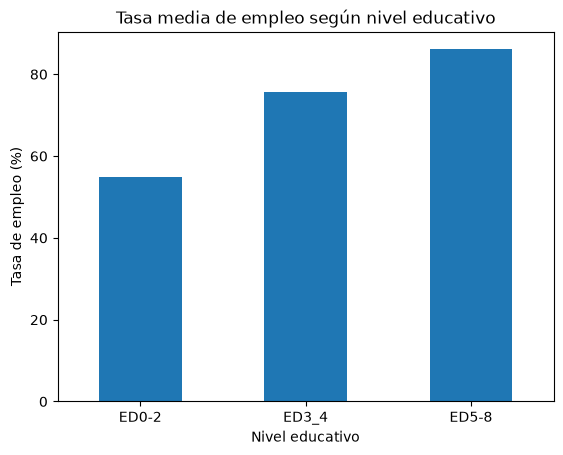

In [79]:
import matplotlib.pyplot as plt

empleo_educacion = df.groupby("isced11")["OBS_VALUE"].mean()

empleo_educacion.plot(kind="bar")

plt.title("Tasa media de empleo según nivel educativo")
plt.xlabel("Nivel educativo")
plt.ylabel("Tasa de empleo (%)")
plt.xticks(rotation=0)
plt.show()

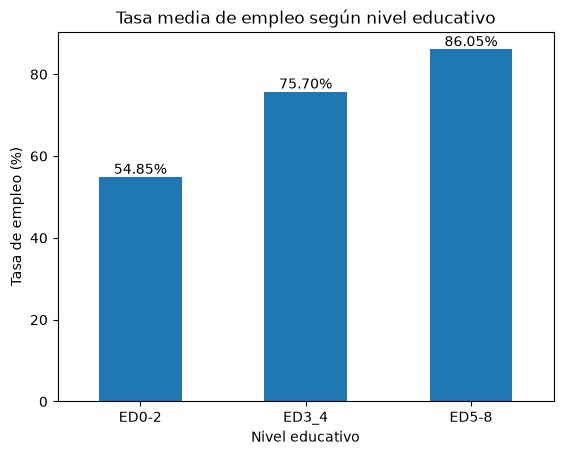

In [80]:
import matplotlib.pyplot as plt

empleo_educacion = df.groupby("isced11")["OBS_VALUE"].mean()

ax = empleo_educacion.plot(kind="bar")

plt.title("Tasa media de empleo según nivel educativo")
plt.xlabel("Nivel educativo")
plt.ylabel("Tasa de empleo (%)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.show()

График выше наглядно показывает результат H1: чем выше уровень образования, тем выше средний уровень занятости.

In [81]:
empleo_anual = df.groupby(["TIME_PERIOD", "isced11"])["OBS_VALUE"].mean().unstack() # средний уровень занятости по каждому году отдельно для трёх уровней образования

empleo_anual

isced11,ED0-2,ED3_4,ED5-8
TIME_PERIOD,,,
2015,51.765714,72.562857,83.580000
2016,52.711429,73.314286,84.165714
2017,53.982857,74.588571,84.885714
2018,55.088571,75.617143,85.468571
2019,55.717143,76.131429,85.977143
2020,54.467647,74.805882,85.176471
2021,54.055882,75.364706,86.258824
2022,55.667647,77.082353,87.385294
2023,56.658824,77.438235,87.664706


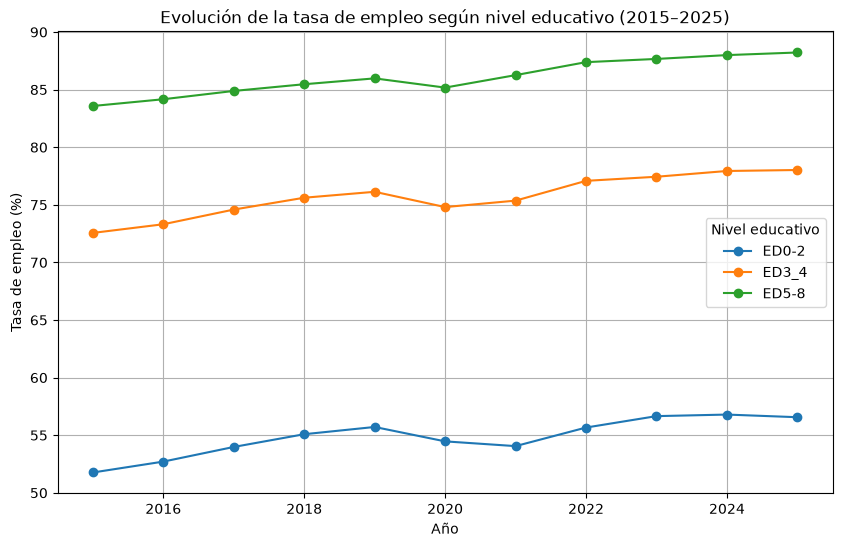

In [82]:
# Рисуем график с линиями для каждого уровня образования по годам

empleo_anual.plot(kind="line", marker="o", figsize=(10, 6))

plt.title("Evolución de la tasa de empleo según nivel educativo (2015–2025)")
plt.xlabel("Año")
plt.ylabel("Tasa de empleo (%)")
plt.legend(title="Nivel educativo")
plt.grid(True)
plt.show()

In [83]:
brecha_educativa = empleo_anual["ED5-8"] - empleo_anual["ED0-2"]

brecha_educativa.round(2)

TIME_PERIOD
2015    31.81
2016    31.45
2017    30.90
2018    30.38
2019    30.26
2020    30.71
2021    32.20
2022    31.72
2023    31.01
2024    31.20
2025    31.66
dtype: float64

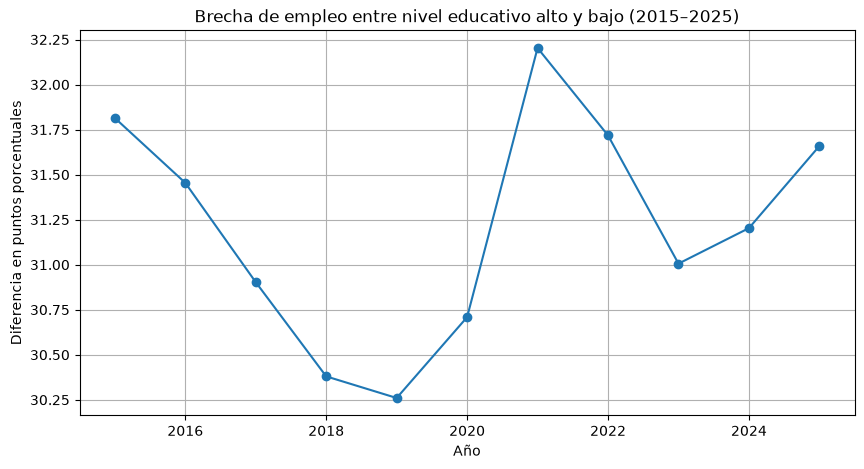

In [84]:
brecha_educativa.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Brecha de empleo entre nivel educativo alto y bajo (2015–2025)")
plt.xlabel("Año")
plt.ylabel("Diferencia en puntos porcentuales")
plt.grid(True)
plt.show()

«La pandemia de COVID-19 podría haber influido en la evolución de la brecha de empleo entre los distintos niveles educativos, especialmente durante 2020 y 2021. Esta relación requiere un análisis más profundo.»

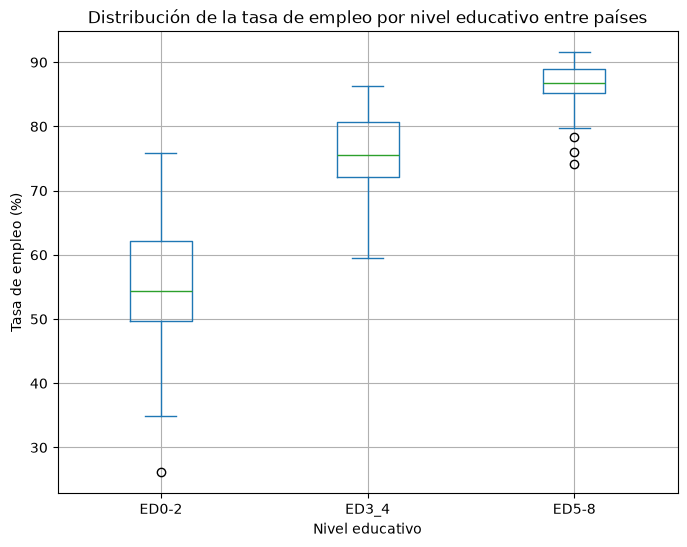

In [85]:
empleo_pais = df.groupby(["geo", "isced11"])["OBS_VALUE"].mean().unstack()

empleo_pais[["ED0-2", "ED3_4", "ED5-8"]].plot(
    kind="box",
    figsize=(8, 6)
)

plt.title("Distribución de la tasa de empleo por nivel educativo entre países")
plt.xlabel("Nivel educativo")
plt.ylabel("Tasa de empleo (%)")
plt.grid(True)
plt.show()

In [86]:
empleo_pais.idxmin()

isced11
ED0-2    BA
ED3_4    ME
ED5-8    TR
dtype: str

In [87]:
empleo_pais.idxmax()

isced11
ED0-2    IS
ED3_4    IS
ED5-8    IS
dtype: str

In [88]:
empleo_pais.loc[["BA", "ME", "TR", "IS"]].round(2) #

isced11,ED0-2,ED3_4,ED5-8
geo,,,
BA,26.10,61.90,81.14
ME,34.97,59.43,78.33
TR,48.14,61.49,74.21
IS,75.83,86.27,91.52


Наблюдение: Исландия показывает самые высокие средние значения занятости во всех образовательных группах. В Боснии и Герцеговине особенно низкая занятость среди людей с низким уровнем образования — 26,10%.

Это подчёркивает, что различия связаны не только с уровнем образования, но и с контекстом конкретной страны.

In [89]:
brecha_pais = empleo_pais["ED5-8"] - empleo_pais["ED0-2"]

brecha_pais.sort_values(ascending=False).round(2)

geo
BA    55.04
SK    50.15
HR    46.18
PL    43.73
ME    43.37
MK    42.56
BG    41.15
LT    40.18
RO    39.59
BE    39.52
SI    37.89
IE    32.85
FR    32.45
FI    32.35
CZ    32.22
AT    31.32
HU    31.01
RS    30.48
IT    29.31
NO    28.30
LV    28.18
SE    27.34
MT    26.37
DE    26.35
DK    26.16
TR    26.07
LU    25.55
NL    24.75
ES    23.80
EL    23.02
UK    22.24
EE    21.99
CH    20.91
CY    19.63
PT    19.37
IS    15.69
dtype: float64

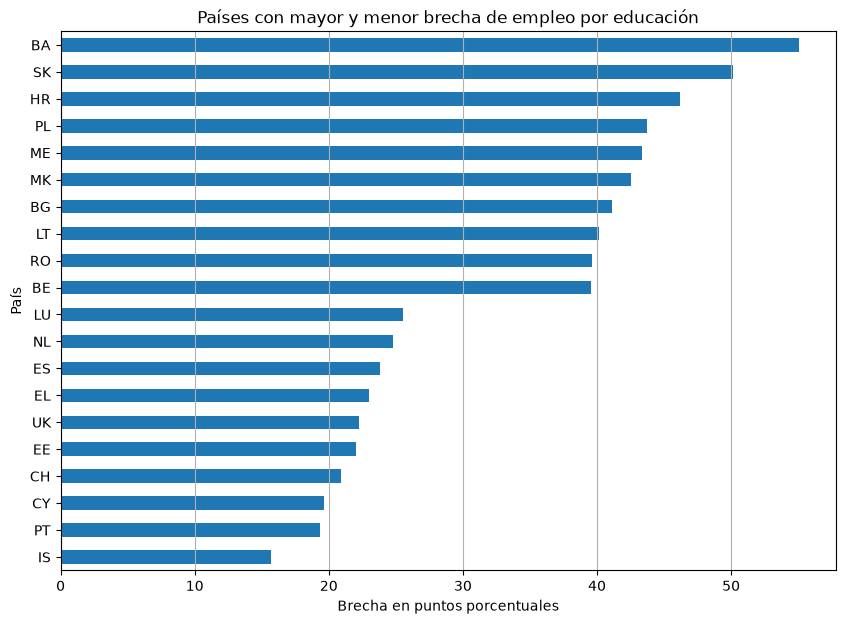

In [90]:
brecha_extremos = pd.concat([
    brecha_pais.sort_values(ascending=False).head(10),
    brecha_pais.sort_values().head(10)
]).sort_values()

brecha_extremos.plot(kind="barh", figsize=(10, 7))

plt.title("Países con mayor y menor brecha de empleo por educación")
plt.xlabel("Brecha en puntos porcentuales")
plt.ylabel("País")
plt.grid(axis="x")
plt.show()

Он наглядно показывает, что разрыв в уровне занятости между людьми с высоким и низким образованием существенно отличается в разных странах.

### Conclusión H1

Los resultados del análisis exploratorio confirman la hipótesis H1. Se observa una relación positiva entre el nivel educativo y la tasa de empleo: cuanto mayor es el nivel educativo, mayor es la tasa media de empleo.

La tasa media de empleo es del 54,85% para las personas con bajo nivel educativo, del 75,70% para el nivel medio y del 86,05% para el nivel alto.

Además, la brecha entre los niveles educativos varía considerablemente entre países, siendo más elevada en Bosnia y Herzegovina (BA) y más reducida en Islandia (IS).

Estos resultados muestran una asociación entre educación y empleo, aunque no permiten establecer una relación causal.

In [91]:
df["sex"].unique()

<StringArray>
['T']
Length: 1, dtype: str

In [92]:
df_original["sex"].unique()

NameError: name 'df_original' is not defined

--------------------------------------
""Hiipotesa 2""

In [93]:
df_migracion = pd.read_csv("../Data/raw/lfsa_erganedm__custom_23902426_linear_2_0.csv")

In [94]:
df_migracion.head()

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,isced11,International Standard Classification of Education (ISCED 2011),citizen,Country of citizenship,mgstatus,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:LFSA_ERGANEDM(1.0),"Employment rates by migration status, citizens...",A,Annual,ED0-2,"Less than primary, primary and lower secondary...",TOTAL,Total,FBO,...,AT,Austria,2021,NaN,37.8,NaN,b,break in time series,NaN,NaN
1,dataflow,ESTAT:LFSA_ERGANEDM(1.0),"Employment rates by migration status, citizens...",A,Annual,ED0-2,"Less than primary, primary and lower secondary...",TOTAL,Total,FBO,...,AT,Austria,2022,NaN,38.7,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:LFSA_ERGANEDM(1.0),"Employment rates by migration status, citizens...",A,Annual,ED0-2,"Less than primary, primary and lower secondary...",TOTAL,Total,FBO,...,AT,Austria,2023,NaN,41.4,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:LFSA_ERGANEDM(1.0),"Employment rates by migration status, citizens...",A,Annual,ED0-2,"Less than primary, primary and lower secondary...",TOTAL,Total,FBO,...,AT,Austria,2024,NaN,44.1,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:LFSA_ERGANEDM(1.0),"Employment rates by migration status, citizens...",A,Annual,ED0-2,"Less than primary, primary and lower secondary...",TOTAL,Total,FBO,...,AT,Austria,2025,NaN,43.2,NaN,NaN,NaN,NaN,NaN


In [95]:
df_migracion.shape

(27640, 27)

In [96]:
df_migracion.info()

<class 'pandas.DataFrame'>
RangeIndex: 27640 entries, 0 to 27639
Data columns (total 27 columns):
 #   Column                                                           Non-Null Count  Dtype  
---  ------                                                           --------------  -----  
 0   STRUCTURE                                                        27640 non-null  str    
 1   STRUCTURE_ID                                                     27640 non-null  str    
 2   STRUCTURE_NAME                                                   27640 non-null  str    
 3   freq                                                             27640 non-null  str    
 4   Time frequency                                                   27640 non-null  str    
 5   isced11                                                          27640 non-null  str    
 6   International Standard Classification of Education (ISCED 2011)  27640 non-null  str    
 7   citizen                                            

In [ ]:
df_migracion.isnull().sum()# Comprobamos la cantidad de valores nulos en cada columna

STRUCTURE                                                              0
STRUCTURE_ID                                                           0
STRUCTURE_NAME                                                         0
freq                                                                   0
Time frequency                                                         0
isced11                                                                0
International Standard Classification of Education (ISCED 2011)        0
citizen                                                                0
Country of citizenship                                                 0
mgstatus                                                               0
Migration status                                                       0
age                                                                    0
Age class                                                              0
sex                                                

In [ ]:
df_migracion.duplicated().sum() # Comprobamos si existen filas duplicadas

np.int64(0)

In [99]:
df_migracion.describe()

,TIME_PERIOD,Time,OBS_VALUE,Observation value,CONF_STATUS,Confidentiality status (flag)
count,27640.000000,0.0,24528.000000,0.0,0.0,0.0
mean,2023.006512,NaN,65.052014,NaN,NaN,NaN
std,1.414864,NaN,14.492785,NaN,NaN,NaN
min,2021.000000,NaN,8.100000,NaN,NaN,NaN
25%,2022.000000,NaN,57.700000,NaN,NaN,NaN
50%,2023.000000,NaN,67.200000,NaN,NaN,NaN
75%,2024.000000,NaN,75.200000,NaN,NaN,NaN
max,2025.000000,NaN,100.000000,NaN,NaN,NaN


In [ ]:
df_migracion["mgstatus"].value_counts()# Analizamos la frecuencia de cada categoría de estado migratorio

mgstatus
NBO             3231
NBO_NAT         3231
TOTAL           3231
FBO             3226
FBO_NBO_ABR     3226
NBO_ABR         3181
NBO_ABR_PAR1    3171
NBO_ABR_PAR2    3091
UNK             2052
Name: count, dtype: int64

In [ ]:
df_migracion["isced11"].value_counts()# Analizamos la frecuencia de cada categoría del nivel educativo

isced11
TOTAL      4669
ED3_4      4650
ED5-8      4637
ED35_45    4624
ED0-2      4600
ED34_44    4460
Name: count, dtype: int64

In [103]:
# Analizamos la distribución por sexo
df_migracion["sex"].value_counts()

sex
T    9257
F    9199
M    9184
Name: count, dtype: int64

In [104]:
# Analizamos la distribución de las observaciones por país
df_migracion["geo"].value_counts()

geo
BE           810
CH           810
DK           810
EA21         810
EE           810
EL           810
EU27_2020    810
FR           810
IE           810
IT           810
LT           810
LV           810
PT           810
SI           810
FI           809
NL           807
HU           802
DE           791
HR           791
CZ           789
TR           789
BA           786
IS           761
LU           726
RS           724
AT           720
ES           720
NO           720
PL           720
SE           720
SK           715
BG           710
CY           708
MT           706
RO           682
MK           604
Name: count, dtype: int64

In [106]:
# Analizamos la distribución de las observaciones por grupo de edad
df_migracion["age"].value_counts()

age
Y25-74    27640
Name: count, dtype: int64

In [107]:
# Analizamos la distribución de las observaciones por año
df_migracion["TIME_PERIOD"].value_counts().sort_index()

TIME_PERIOD
2021    5506
2022    5489
2023    5532
2024    5545
2025    5568
Name: count, dtype: int64

In [108]:
# Excluimos los agregados de la Unión Europea y de la zona euro
df_migracion = df_migracion[~df_migracion["geo"].isin(["EU27_2020", "EA21"])]

In [109]:
# Comprobamos los países y agregados geográficos disponibles
df_migracion["geo"].value_counts()

geo
BE    810
CH    810
DK    810
EE    810
EL    810
FR    810
IE    810
IT    810
LT    810
LV    810
PT    810
SI    810
FI    809
NL    807
HU    802
DE    791
HR    791
CZ    789
TR    789
BA    786
IS    761
LU    726
RS    724
AT    720
ES    720
NO    720
PL    720
SE    720
SK    715
BG    710
CY    708
MT    706
RO    682
MK    604
Name: count, dtype: int64

In [110]:
# Comprobamos las dimensiones del DataFrame después del filtrado
df_migracion.shape

(26020, 27)

In [111]:
# Analizamos la distribución de las observaciones por año
df_migracion["TIME_PERIOD"].value_counts().sort_index()

TIME_PERIOD
2021    5182
2022    5165
2023    5208
2024    5221
2025    5244
Name: count, dtype: int64

In [112]:
# Comprobamos el número de países incluidos en el análisis
df_migracion["geo"].nunique()

34

In [113]:
# Mostramos los países incluidos en el análisis
df_migracion["geo"].unique()

<StringArray>
['AT', 'BA', 'BE', 'BG', 'CH', 'CY', 'CZ', 'DE', 'DK', 'EE', 'EL', 'ES', 'FI',
 'FR', 'HR', 'HU', 'IE', 'IS', 'IT', 'LT', 'LU', 'LV', 'MK', 'MT', 'NL', 'NO',
 'PL', 'PT', 'RO', 'RS', 'SE', 'SI', 'SK', 'TR']
Length: 34, dtype: str

In [114]:
# Comprobamos los valores nulos en la variable principal del análisis
df_migracion["OBS_VALUE"].isnull().sum()

np.int64(3112)

In [115]:
# Comprobamos si existen filas duplicadas después de excluir los agregados
df_migracion.duplicated().sum()

np.int64(0)

In [116]:
# Calculamos el porcentaje de valores nulos en la variable principal
(df_migracion["OBS_VALUE"].isnull().sum() / len(df_migracion) * 100).round(2)

np.float64(11.96)

In [117]:
# Analizamos los valores nulos de OBS_VALUE según el estado migratorio
df_migracion[df_migracion["OBS_VALUE"].isnull()]["mgstatus"].value_counts()

mgstatus
UNK             984
NBO_ABR_PAR2    872
NBO_ABR_PAR1    461
NBO_ABR         379
FBO             234
FBO_NBO_ABR     168
NBO               5
NBO_NAT           5
TOTAL             4
Name: count, dtype: int64

In [118]:
# Analizamos los valores nulos de OBS_VALUE según el año
df_migracion[df_migracion["OBS_VALUE"].isnull()]["TIME_PERIOD"].value_counts().sort_index()

TIME_PERIOD
2021    590
2022    580
2023    637
2024    636
2025    669
Name: count, dtype: int64

In [119]:
# Analizamos los valores nulos de OBS_VALUE según el sexo
df_migracion[df_migracion["OBS_VALUE"].isnull()]["sex"].value_counts()

sex
F    1251
M    1038
T     823
Name: count, dtype: int64

In [120]:
# Analizamos los valores nulos de OBS_VALUE según el nivel educativo
df_migracion[df_migracion["OBS_VALUE"].isnull()]["isced11"].value_counts()

isced11
ED0-2      911
ED34_44    704
ED35_45    474
ED5-8      399
ED3_4      361
TOTAL      263
Name: count, dtype: int64

In [121]:
# Analizamos los valores nulos de OBS_VALUE según el país
df_migracion[df_migracion["OBS_VALUE"].isnull()]["geo"].value_counts()

geo
RO    349
BG    345
BA    260
SK    226
FI    181
IS    165
HU    153
IE    131
PL    126
MT    105
LU    103
CY     94
PT     91
HR     85
NL     77
LT     74
NO     67
EL     65
TR     57
LV     56
CZ     50
IT     48
MK     38
DK     37
CH     36
SI     30
EE     25
DE     18
RS      7
BE      6
AT      3
SE      2
ES      2
Name: count, dtype: int64

In [122]:
# Calculamos el porcentaje de valores nulos de OBS_VALUE por país
(df_migracion.groupby("geo")["OBS_VALUE"]
 .apply(lambda x: x.isnull().mean() * 100)
 .sort_values(ascending=False)
 .round(2))

geo
RO    51.17
BG    48.59
BA    33.08
SK    31.61
FI    22.37
IS    21.68
HU    19.08
PL    17.50
IE    16.17
MT    14.87
LU    14.19
CY    13.28
PT    11.23
HR    10.75
NL     9.54
NO     9.31
LT     9.14
EL     8.02
TR     7.22
LV     6.91
CZ     6.34
MK     6.29
IT     5.93
DK     4.57
CH     4.44
SI     3.70
EE     3.09
DE     2.28
RS     0.97
BE     0.74
AT     0.42
ES     0.28
SE     0.28
FR     0.00
Name: OBS_VALUE, dtype: float64

<Axes: >

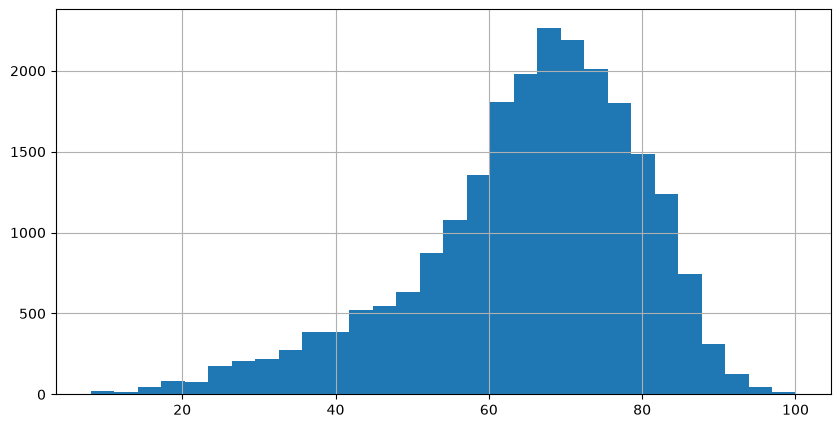

In [123]:
# Visualizamos la distribución de OBS_VALUE mediante un histograma
df_migracion["OBS_VALUE"].hist(bins=30, figsize=(10, 5))

In [124]:
# Calculamos la asimetría de la distribución de OBS_VALUE
df_migracion["OBS_VALUE"].skew().round(2)

np.float64(-0.83)

In [125]:
# Calculamos la curtosis de la distribución de OBS_VALUE
df_migracion["OBS_VALUE"].kurt().round(2)

np.float64(0.62)

<Axes: >

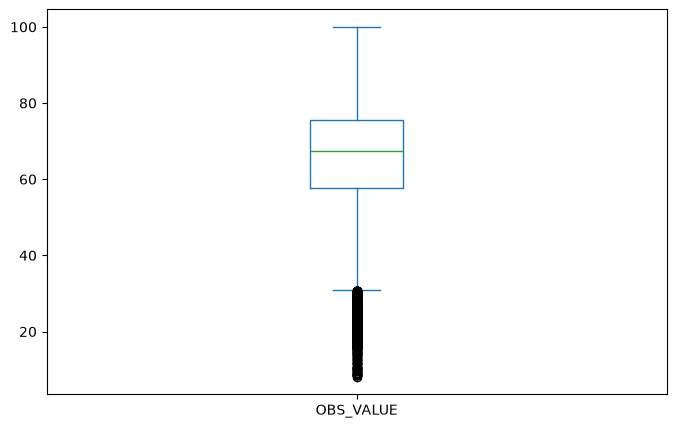

In [126]:
# Visualizamos los posibles valores atípicos de OBS_VALUE mediante un boxplot
df_migracion["OBS_VALUE"].plot(kind="box", figsize=(8, 5))

In [127]:
# Calculamos los límites del IQR y el número de valores atípicos
Q1 = df_migracion["OBS_VALUE"].quantile(0.25)
Q3 = df_migracion["OBS_VALUE"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df_migracion[
    (df_migracion["OBS_VALUE"] < limite_inferior) |
    (df_migracion["OBS_VALUE"] > limite_superior)
]

print("Límite inferior:", round(limite_inferior, 2))
print("Límite superior:", round(limite_superior, 2))
print("Número de valores atípicos:", len(outliers))

Límite inferior: 30.75
Límite superior: 102.35
Número de valores atípicos: 687


In [128]:
# Mostramos los 10 valores más bajos de OBS_VALUE
outliers[["geo", "sex", "isced11", "mgstatus", "TIME_PERIOD", "OBS_VALUE"]].sort_values(
    "OBS_VALUE"
).head(10)

,geo,sex,isced11,mgstatus,TIME_PERIOD,OBS_VALUE
4260,BE,F,ED0-2,UNK,2021,8.1
3181,BA,F,ED0-2,NBO_NAT,2022,8.5
1086,BA,F,ED0-2,NBO,2022,8.6
3721,BA,F,ED0-2,TOTAL,2022,8.6
4303,FI,F,ED0-2,UNK,2021,8.7
27313,EL,F,TOTAL,UNK,2023,8.8
3182,BA,F,ED0-2,NBO_NAT,2023,9.0
1087,BA,F,ED0-2,NBO,2023,9.0
3722,BA,F,ED0-2,TOTAL,2023,9.1
1088,BA,F,ED0-2,NBO,2024,9.7


<Axes: title={'center': 'OBS_VALUE'}, xlabel='sex'>

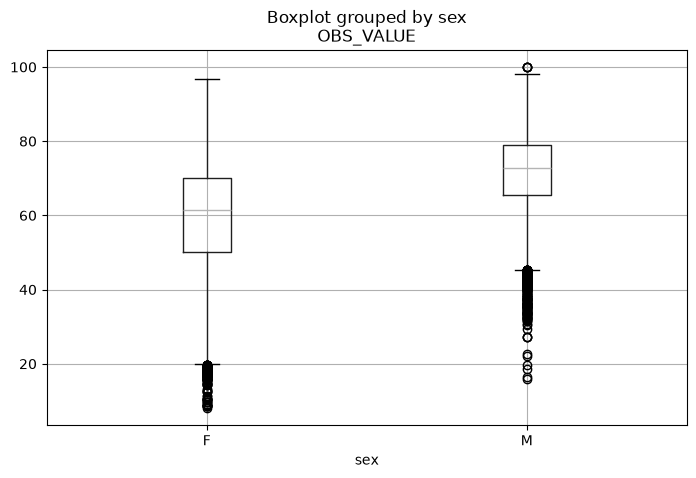

In [129]:
# Comparamos la distribución de OBS_VALUE entre mujeres y hombres
df_migracion[df_migracion["sex"].isin(["F", "M"])].boxplot(
    column="OBS_VALUE",
    by="sex",
    figsize=(8, 5)
)

In [130]:
# Calculamos la media y la mediana de OBS_VALUE por sexo
df_migracion[df_migracion["sex"].isin(["F", "M"])].groupby("sex")["OBS_VALUE"].agg(
    ["mean", "median", "std"]
).round(2)

,mean,median,std
sex,,,
F,59.16,61.5,16.09
M,71.23,72.9,11.46


<Axes: title={'center': 'OBS_VALUE'}, xlabel='isced11'>

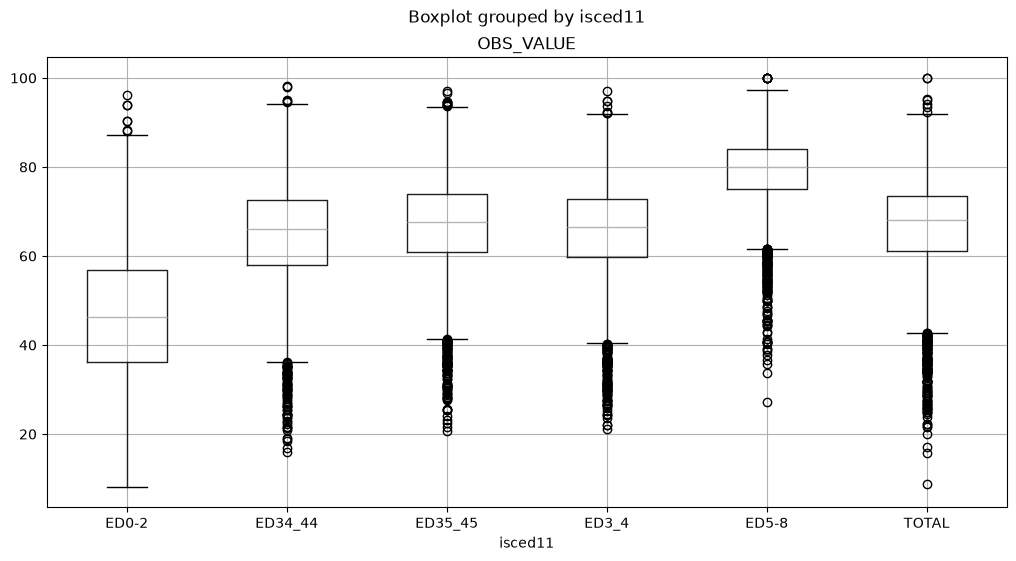

In [131]:
# Comparamos la distribución de OBS_VALUE según el nivel educativo
df_migracion.boxplot(
    column="OBS_VALUE",
    by="isced11",
    figsize=(12, 6)
)

In [132]:
# Calculamos la media, mediana y desviación estándar por nivel educativo
df_migracion.groupby("isced11")["OBS_VALUE"].agg(
    ["mean", "median", "std", "count"]
).round(2)

,mean,median,std,count
isced11,,,,
ED0-2,46.27,46.4,14.78,3419
ED34_44,64.71,66.1,11.92,3486
ED35_45,66.64,67.6,11.11,3880
ED3_4,65.40,66.5,11.06,4019
ED5-8,78.76,80.1,8.18,3968
TOTAL,66.32,68.0,10.98,4136


<Axes: xlabel='TIME_PERIOD'>

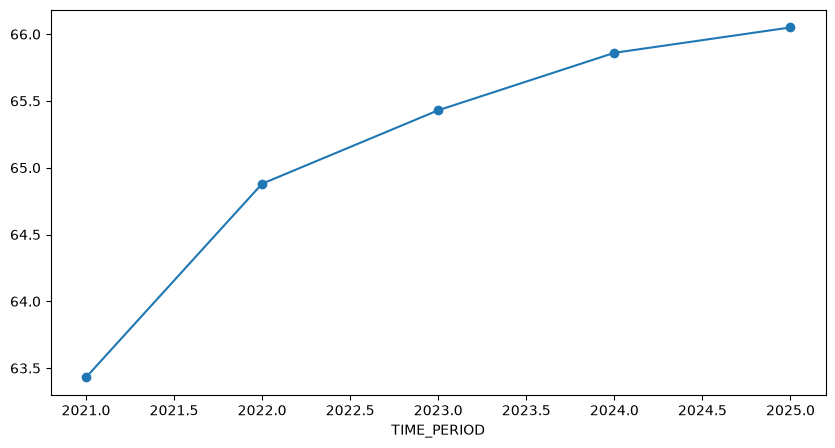

In [133]:
# Analizamos la evolución de OBS_VALUE a lo largo del tiempo
df_migracion.groupby("TIME_PERIOD")["OBS_VALUE"].mean().round(2).plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

<Axes: xlabel='TIME_PERIOD'>

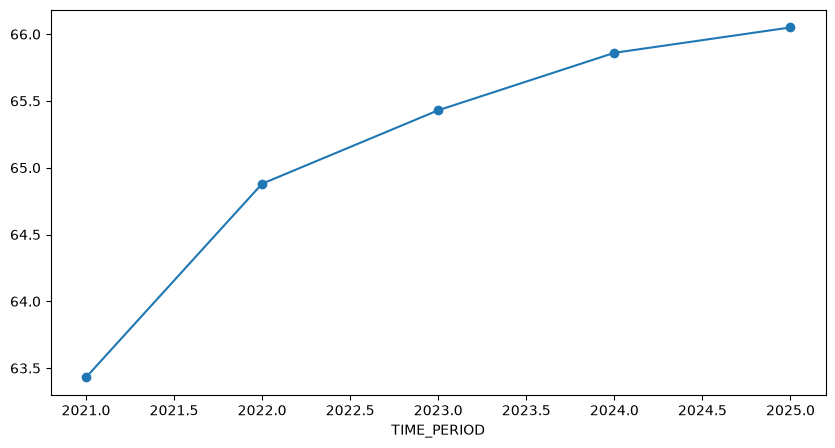

In [134]:
# Analizamos la evolución de OBS_VALUE a lo largo del tiempo
df_migracion.groupby("TIME_PERIOD")["OBS_VALUE"].mean().round(2).plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

<Axes: title={'center': 'Evolución de OBS_VALUE por sexo'}, xlabel='TIME_PERIOD'>

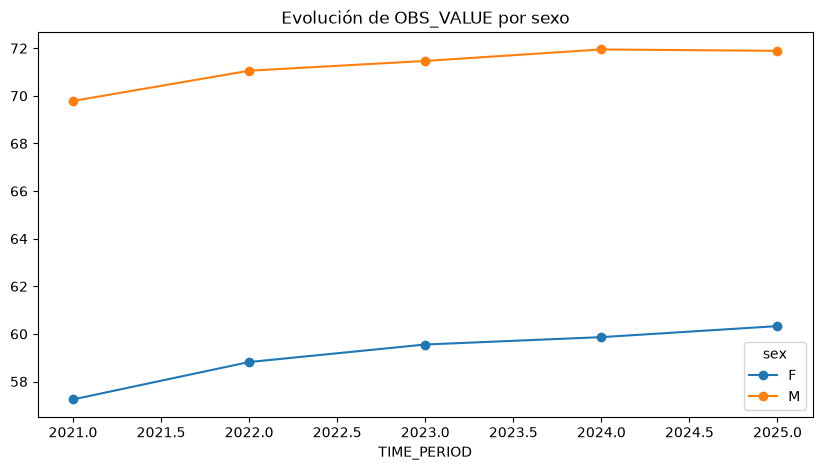

In [135]:
# Comparamos la evolución de OBS_VALUE por año y sexo
df_migracion[df_migracion["sex"].isin(["F", "M"])].pivot_table(
    index="TIME_PERIOD",
    columns="sex",
    values="OBS_VALUE",
    aggfunc="mean"
).plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Evolución de OBS_VALUE por sexo"
)

In [136]:
# Mostramos las categorías de situación migratoria
df_migracion["mgstatus"].value_counts()

mgstatus
NBO             3051
NBO_NAT         3051
TOTAL           3051
FBO             3046
FBO_NBO_ABR     3046
NBO_ABR         3001
NBO_ABR_PAR1    2991
NBO_ABR_PAR2    2911
UNK             1872
Name: count, dtype: int64

Код	Значение
FBO	Родившиеся за границей — мигранты первого поколения
NBO	Родившиеся в стране
NBO_NAT	Родившиеся в стране, оба родителя тоже родились в стране
NBO_ABR	Родившиеся в стране, один или оба родителя родились за границей
NBO_ABR_PAR1	Один родитель родился за границей
NBO_ABR_PAR2	Оба родителя родились за границей
FBO_NBO_ABR	Родившиеся за границей или местные жители с родителями-иностранцами
TOTAL	Все вместе
UNK	Неизвестно

In [137]:
# Seleccionamos dos grupos para comparar
df_h2 = df_migracion[
    df_migracion["mgstatus"].isin(["FBO", "NBO_NAT"])
]

# Comprobamos las categorías seleccionadas
df_h2["mgstatus"].value_counts()

mgstatus
NBO_NAT    3051
FBO        3046
Name: count, dtype: int64

In [138]:
# Comprobamos los valores disponibles para el análisis
df_h2["OBS_VALUE"].notna().sum()

np.int64(5858)

In [139]:
# Comprobamos los valores ausentes
df_h2["OBS_VALUE"].isna().sum()

np.int64(239)

In [140]:
# Eliminamos las filas sin valores de empleo
df_h2_clean = df_h2.dropna(subset=["OBS_VALUE"]).copy()

# Comprobamos el resultado
df_h2_clean.shape

(5858, 27)

In [141]:
# Calculamos la tasa media de empleo por nivel educativo y situación migratoria
df_h2_clean.groupby(["isced11", "mgstatus"])["OBS_VALUE"].mean().round(2)

isced11  mgstatus
ED0-2    FBO         52.34
         NBO_NAT     41.07
ED34_44  FBO         63.74
         NBO_NAT     65.36
ED35_45  FBO         66.66
         NBO_NAT     67.62
ED3_4    FBO         65.12
         NBO_NAT     66.36
ED5-8    FBO         74.21
         NBO_NAT     81.46
TOTAL    FBO         65.50
         NBO_NAT     66.65
Name: OBS_VALUE, dtype: float64

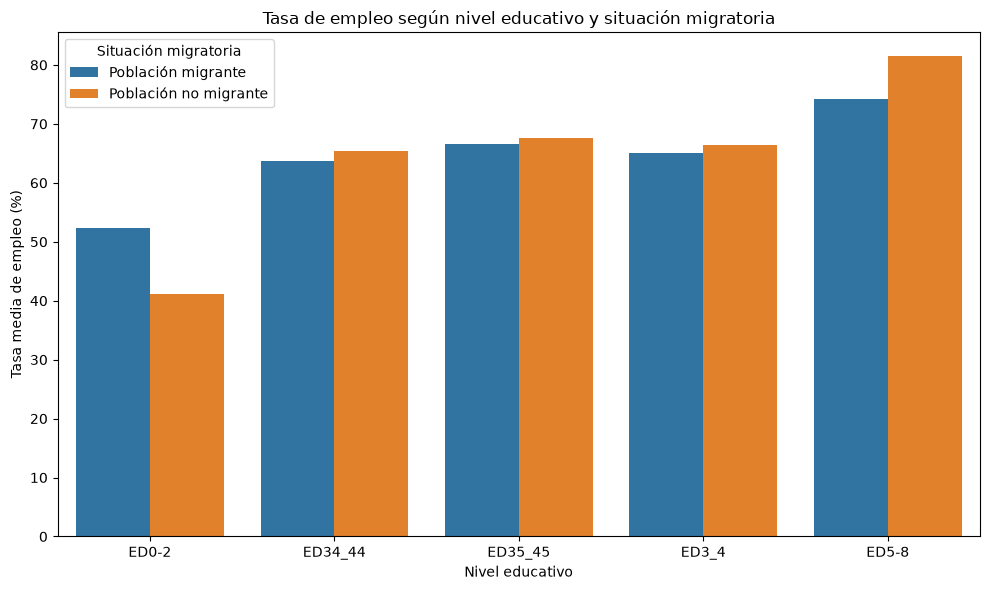

In [144]:
# Calculamos la tasa media por nivel educativo y situación migratoria
df_h2_plot = (
    df_h2_clean[df_h2_clean["isced11"] != "TOTAL"]
    .groupby(["isced11", "mgstatus"], as_index=False)["OBS_VALUE"]
    .mean()
)

# Creamos el gráfico comparativo
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
# Sustituimos los códigos por nombres más descriptivos
df_h2_plot["mgstatus"] = df_h2_plot["mgstatus"].replace({
    "FBO": "Población migrante",
    "NBO_NAT": "Población no migrante"
})

sns.barplot(
    data=df_h2_plot,
    x="isced11",
    y="OBS_VALUE",
    hue="mgstatus"
)

plt.title("Tasa de empleo según nivel educativo y situación migratoria")
plt.xlabel("Nivel educativo")
plt.ylabel("Tasa media de empleo (%)")
plt.legend(title="Situación migratoria")
plt.tight_layout()
plt.show()